### Using code from NR 06_Atlas_generation_visualise/2026-03-22_DC2_Updaated_annotations.ipynb
* NR used the DC2 heatmaps generated from the Mulder et al 2025 data to rename the 10 DC2 clusters 

In [1]:
# Load required packages
import os
import tools
import scanpy as sc
import pandas as pd
import dandelion as ddl
from tqdm import tqdm
import matplotlib.pyplot as plt
import scanpy.external as sce
from matplotlib.pyplot import rc_context
import seaborn as sns

/home/uqlbukat/.local/lib/python3.11/site-packages/nxviz/__init__.py:33: UserWarning: 
nxviz has a new API! Version 0.7.4 onwards, the old class-based API is being
deprecated in favour of a new API focused on advancing a grammar of network
graphics. If your plotting code depends on the old API, please consider
pinning nxviz at version 0.7.4, as the new API will break your old code.

To check out the new API, please head over to the docs at
https://ericmjl.github.io/nxviz/ to learn more. We hope you enjoy using it!

(This deprecation message will go away in version 1.0.)



In [3]:
#set working directory
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026')
os.getcwd()

'/scratch/user/uqlbukat/NRAtlas_analysis_2026'

In [4]:
# read in data
data_DC = sc.read_h5ad('20250617_AllDC_bbknn.h5ad')
#data = sc.read_h5ad('NRclean_clustered2.h5ad') This has all the myeloid data
data_DC2 = sc.read_h5ad('20250629_DC2_bbknn_clustered2.h5ad')

In [5]:
# Set colours for NR_annotations_simple plot:
data_DC.uns["NR_annotations_simple_colors"] = ['#e377c2', '#aa40fc', '#8c564b']  

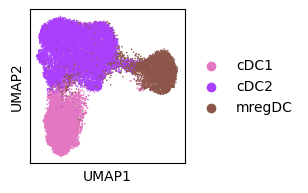

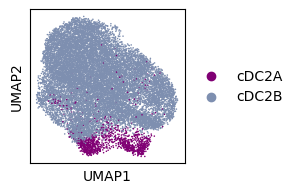

In [6]:
#output umap
with plt.rc_context({"figure.figsize": (2, 2)}):
    sc.pl.umap(data_DC, color="NR_annotations_simple", size=5, title="")
    sc.pl.umap(data_DC2, color="cDC2_A-B", size=5, title="") #Current DC2 UMAP

DC2 clusters

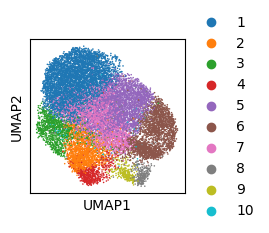

In [7]:
with plt.rc_context({"figure.figsize": (2, 2)}):
    sc.pl.umap(data_DC2, color="cDC2_Atlas_Subclusters", size=5, title="")

In [8]:
# NR set annotations
# Assign DC2 subclusters new:
data_DC2.obs["cDC2_annotated"] = data_DC2.obs["cDC2_Atlas_Subclusters"].map(
    {
        "1": "DC3-like cells",
        "2": "undefined cDC2",
        "3": "IL-1B cDC2",
        "4": "CD207/LTB cDC2A",
        "5": "classical cDC2",
        "6": "ascites classical cDC2",
        "7": "classical cDC2",
        "8": "CD207/LTB cDC2A",
        "9": "CD207/LTB cDC2A",
        "10": "CD207/LTB cDC2A",
    }
)

In [9]:
#only run for UMAPs
sc.set_figure_params(dpi=80, dpi_save=700, vector_friendly=True, format='svg')

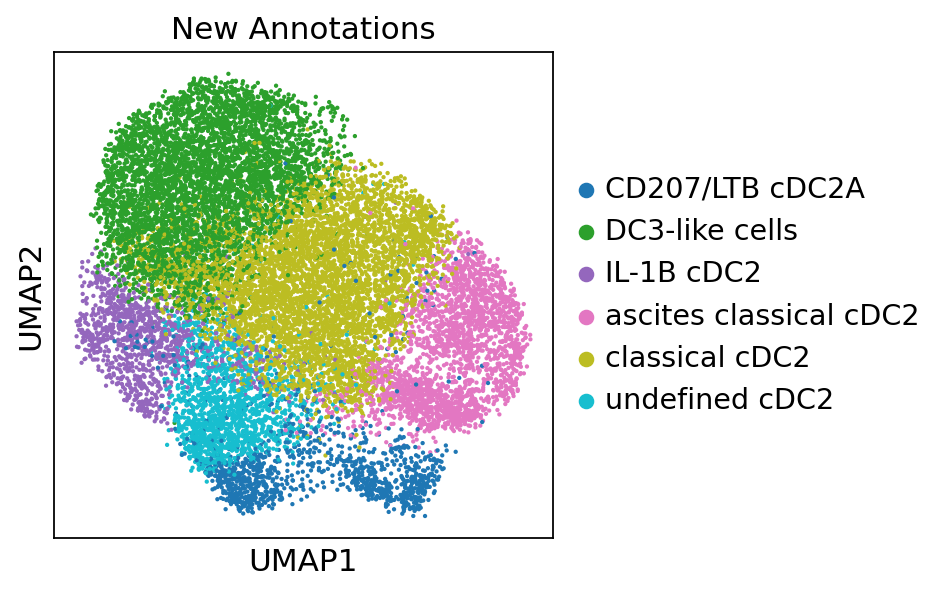

In [10]:
with plt.rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(data_DC2, color="cDC2_annotated", size=15, title="New Annotations", palette="tab10", save="_DC2_annotated.svg")

In [30]:
#save DC2 data with the new annotations
data_DC2.write_h5ad('/scratch/user/uqlbukat/NRAtlas_analysis_2026/newDC2annotations.h5ad')

/home/uqlbukat/.local/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release


In [11]:
#Calculate DEGs between new cDC2 annotations 
sc.tl.rank_genes_groups(data_DC2, groupby="cDC2_annotated", method="wilcoxon", key_added="cDC2_annotated_DEGs")

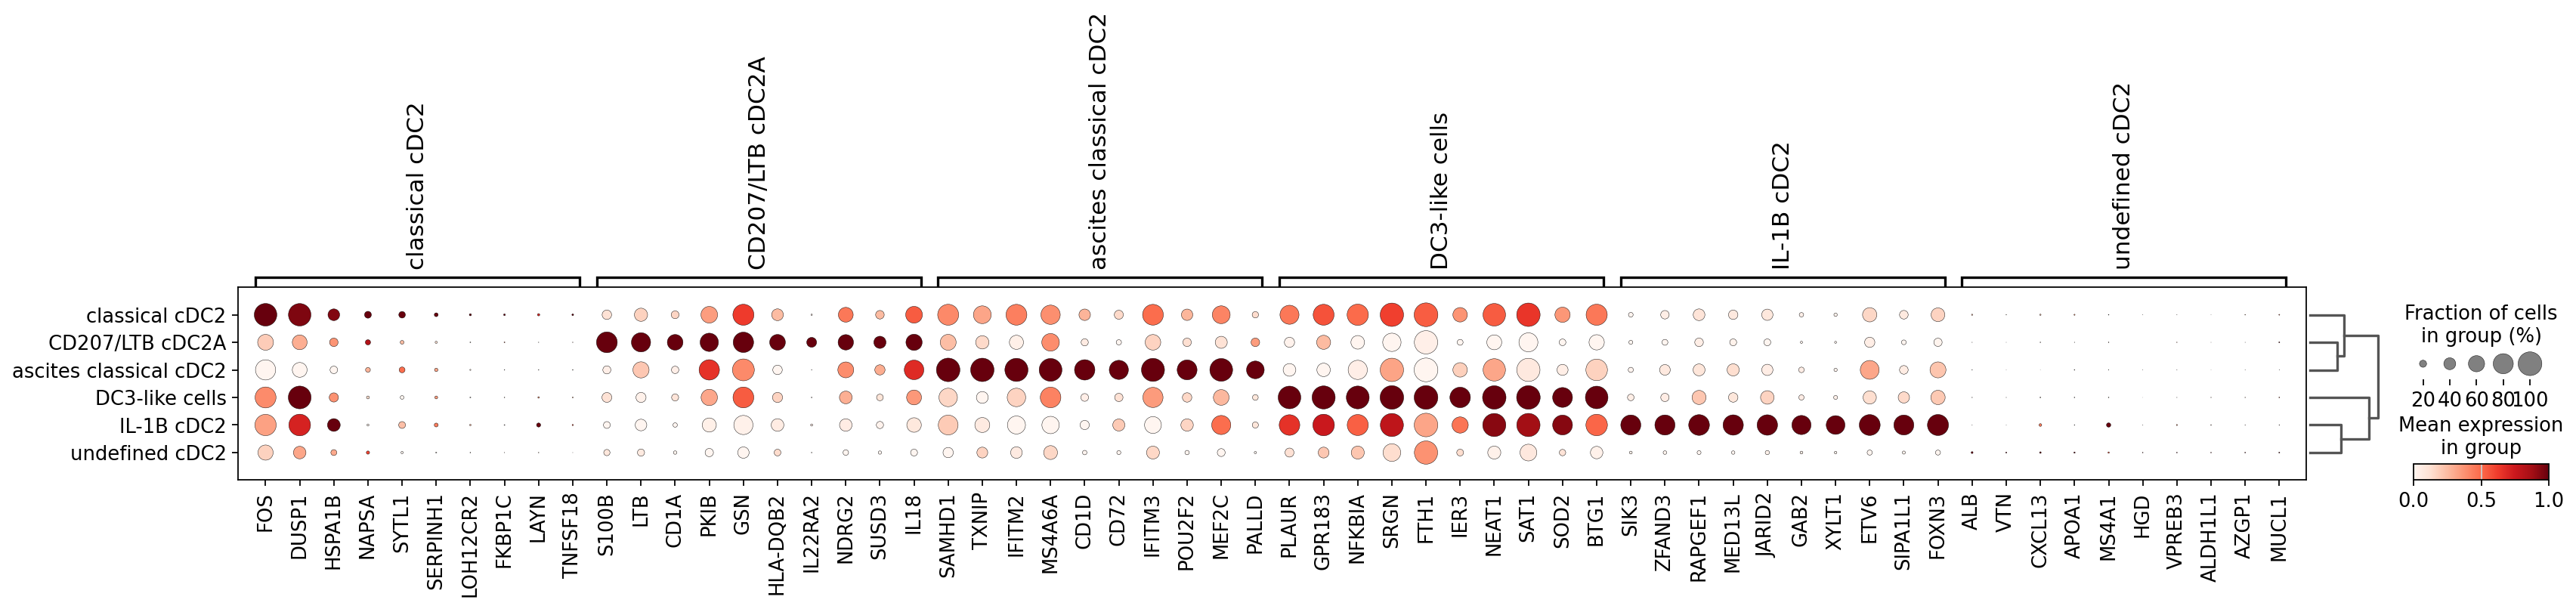

In [12]:
#visualise the top 10 DEG genes for each cluster
sc.pl.rank_genes_groups_dotplot(
    data_DC2, groupby="cDC2_annotated", standard_scale="var", n_genes=10, min_logfoldchange=1, key="cDC2_annotated_DEGs", save="DC2_annotated_degs.svg"
)

In [19]:
# read out for each cluster
DC2_class = sc.get.rank_genes_groups_df(data_DC2, group="classical cDC2", key="cDC2_annotated_DEGs")
DC2_CD207 = sc.get.rank_genes_groups_df(data_DC2, group="CD207/LTB cDC2A", key="cDC2_annotated_DEGs")
DC2_asc = sc.get.rank_genes_groups_df(data_DC2, group="ascites classical cDC2", key="cDC2_annotated_DEGs")
DC2_DC3 = sc.get.rank_genes_groups_df(data_DC2, group="DC3-like cells", key="cDC2_annotated_DEGs")
DC2_IL1b = sc.get.rank_genes_groups_df(data_DC2, group="IL-1B cDC2", key="cDC2_annotated_DEGs")
DC2_unclear = sc.get.rank_genes_groups_df(data_DC2, group="undefined cDC2", key="cDC2_annotated_DEGs")

In [23]:
#set current directory 
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/NewDC2subsets_Analysis')
os.getcwd()

'/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/NewDC2subsets_Analysis'

In [24]:
DC2_class.head()

,names,scores,logfoldchanges,pvals,pvals_adj
0,FOS,45.891388,1.653223,0.000000e+00,0.000000e+00
1,DUSP1,30.089466,1.044479,6.655045e-199,4.681824e-195
2,ZFP36,29.000181,0.944542,6.545125e-185,3.069664e-181
3,ACTB,27.141939,0.591926,3.152281e-162,1.108815e-158
4,JUNB,27.056541,0.852633,3.199185e-161,9.002508e-158


In [25]:
# check what the smallest p value python can output is (set any equal to zero to this)
import numpy as np
np.finfo(np.float64).tiny

#would set floor to this, however excel (which will use for subsequent analysis has a floor of 1e-307, so instead set minimum to this)

np.float64(2.2250738585072014e-308)

In [26]:
# change any p values that are 0.0 to 2.2250738585072014e-308
min_float = 1e-307
DC2_class['pvals'] = DC2_class['pvals'].replace(0.0, min_float)
DC2_class['pvals_adj'] = DC2_class['pvals_adj'].replace(0.0, min_float)
DC2_CD207['pvals'] = DC2_CD207['pvals'].replace(0.0, min_float)
DC2_CD207['pvals_adj'] = DC2_CD207['pvals_adj'].replace(0.0, min_float)
DC2_asc['pvals'] = DC2_asc['pvals'].replace(0.0, min_float)
DC2_asc['pvals_adj'] = DC2_asc['pvals_adj'].replace(0.0, min_float)
DC2_DC3['pvals'] = DC2_DC3['pvals'].replace(0.0, min_float)
DC2_DC3['pvals_adj'] = DC2_DC3['pvals_adj'].replace(0.0, min_float)
DC2_IL1b['pvals'] = DC2_IL1b['pvals'].replace(0.0, min_float)
DC2_IL1b['pvals_adj'] = DC2_IL1b['pvals_adj'].replace(0.0, min_float)
DC2_unclear['pvals'] = DC2_unclear['pvals'].replace(0.0, min_float)
DC2_unclear['pvals_adj'] = DC2_unclear['pvals_adj'].replace(0.0, min_float)

In [27]:
DC2_class.head()

,names,scores,logfoldchanges,pvals,pvals_adj
0,FOS,45.891388,1.653223,1.000000e-307,1.000000e-307
1,DUSP1,30.089466,1.044479,6.655045e-199,4.681824e-195
2,ZFP36,29.000181,0.944542,6.545125e-185,3.069664e-181
3,ACTB,27.141939,0.591926,3.152281e-162,1.108815e-158
4,JUNB,27.056541,0.852633,3.199185e-161,9.002508e-158


In [28]:
# save degs
DC2_class.to_csv("DEGs_newDC2_classicalDC2.csv", index=False)
DC2_CD207.to_csv("DEGs_newDC2_CD207_LTB.csv", index=False)
DC2_asc.to_csv("DEGs_newDC2_AscDC2.csv", index=False)
DC2_DC3.to_csv("DEGs_newDC2_DC3.csv", index=False)
DC2_IL1b.to_csv("DEGs_newDC2_IL1B.csv", index=False)
DC2_unclear.to_csv("DEGs_newDC2_unclear_c2.csv", index=False)